In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/bankchurners/BankChurners.csv


#  Bank Customer Churn Prediction: Classification Project

## Introduction and Setup 

Customer churn is a critical problem for banks. Predicting which customers are likely to leave allows the bank to intervene proactively. This notebook performs an Exploratory Data Analysis (EDA) on the BankChurners dataset and develops several machine learning models to classify customers as "Existing Customer" or "Attrited Customer."

We will focus on maximizing the F1-Score for the minority class ("Attrited Customer") to ensure we correctly identify potential leavers (high recall) without an excessive number of false positives (good precision).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,make_scorer,f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("/kaggle/input/bankchurners/BankChurners.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

In [5]:
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [6]:
df = df.drop([
    'CLIENTNUM',
    "Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1",
    "Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2"
], axis=1)

# EDA

Customer Age vs. Attrition

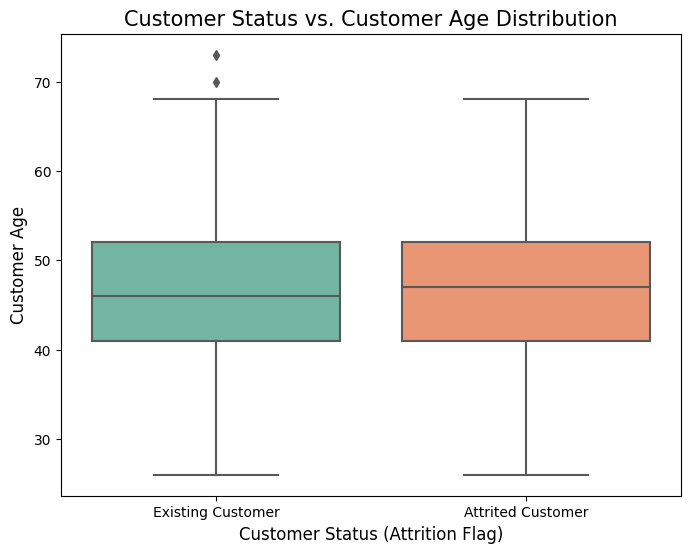

In [7]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="Attrition_Flag", y="Customer_Age", palette="Set2")
plt.title("Customer Status vs. Customer Age Distribution", fontsize=15)
plt.xlabel("Customer Status (Attrition Flag)", fontsize=12)
plt.ylabel("Customer Age", fontsize=12)
plt.show()

Revolving Balance vs. Attrition

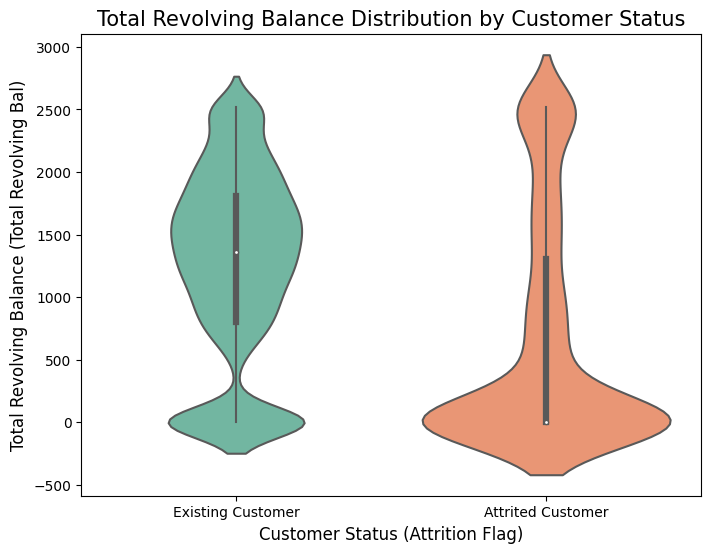

> Insight: Attrited Customers tend to have a lower revolving balance, showing two distinct peaks at the lower end.


In [8]:
plt.figure(figsize=(8, 6))
sns.violinplot(x='Attrition_Flag', y='Total_Revolving_Bal', data=df, palette='Set2')
plt.title('Total Revolving Balance Distribution by Customer Status', fontsize=15)
plt.xlabel('Customer Status (Attrition Flag)', fontsize=12)
plt.ylabel('Total Revolving Balance (Total Revolving Bal)', fontsize=12)
plt.show()

print("> Insight: Attrited Customers tend to have a lower revolving balance, showing two distinct peaks at the lower end.")

**Transaction Change vs. Contacts Count (Key Insight)**

The scatter plot and correlation were critical in identifying a relationship between contact frequency and transaction habits, which appears to be a strong indicator of churn.

The scatter plot showed:

Attrited Customers (Red) are predominantly concentrated in the lower-left quadrant (low change in transaction count and amount).

Existing Customers (Blue) are generally scattered across higher change values.

The correlation was calculated as -0.095. While numerically small, the EDA suggests a pattern where an increase in Contacts_Count_12_mon (i.e., customer service calls) is associated with a decrease in transaction activity (Total_Ct_Chng_Q4_Q1): More service calls + fewer transactions = Higher likelihood of churn.

Correlation between Total_Ct_Chng_Q4_Q1 and Contacts_Count_12_mon: -0.095


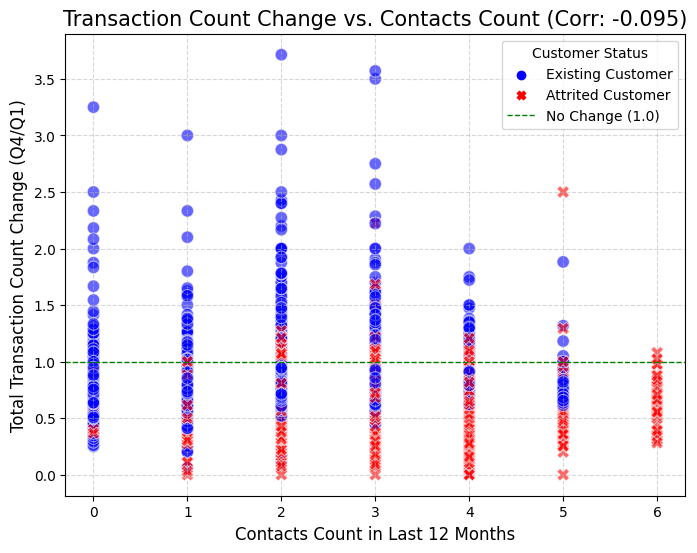

In [9]:
corr = df['Total_Ct_Chng_Q4_Q1'].corr(df['Contacts_Count_12_mon'])
print(f"Correlation between Total_Ct_Chng_Q4_Q1 and Contacts_Count_12_mon: {corr:.3f}")

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='Contacts_Count_12_mon',
    y='Total_Ct_Chng_Q4_Q1',
    hue='Attrition_Flag',
    style='Attrition_Flag',
    palette={'Existing Customer': 'blue', 'Attrited Customer': 'red'},
    alpha=0.6,
    s=80
)
plt.axhline(y=1.0, color='green', linestyle='--', linewidth=1, label='No Change (1.0)')
plt.title(f'Transaction Count Change vs. Contacts Count (Corr: {corr:.3f})', fontsize=15)
plt.xlabel('Contacts Count in Last 12 Months', fontsize=12)
plt.ylabel('Total Transaction Count Change (Q4/Q1)', fontsize=12)
plt.legend(title='Customer Status')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


**Feature Correlation**

The original notebook checked correlations among numerical features. The insight here is that Avg_Open_To_Buy and Credit_Limit are highly correlated (0.99), suggesting one can be removed to reduce multicollinearity.

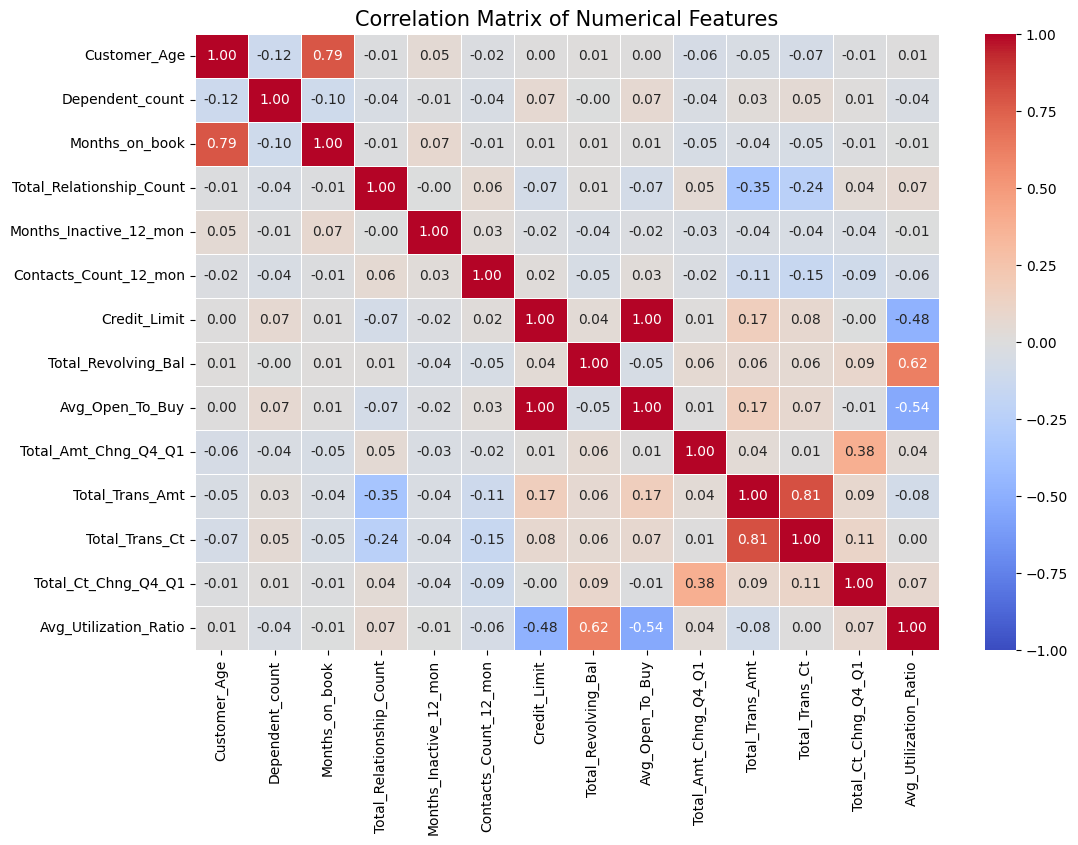

In [10]:
numerical_cols_updated = df.select_dtypes(include=['number']).columns.tolist()
analysis_df = df[numerical_cols_updated]
corr_matrix = analysis_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    linewidths=0.5,
    vmin=-1, vmax=1
)
plt.title('Correlation Matrix of Numerical Features', fontsize=15)
plt.show()

df = df.drop(["Avg_Open_To_Buy"], axis=1)

# Data Preprocessing and Splitting 

In [11]:
categorical_cols = ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]
df = pd.get_dummies(df, columns=categorical_cols, dtype=int)


df_target = df["Attrition_Flag"]
df_features = df.drop("Attrition_Flag", axis=1)

X = df_features
y = df_target


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

# Classification Modeling and Evaluation

We use three different classifiers and tune their hyperparameters using GridSearchCV. We focus on the F1-Score as the primary metric for optimization, as it balances Precision and Recall for the minority (churn) class. We also use class_weight='balanced' to address the class imbalance.

**The target classes are:**

Attrited Customer (Minority Class, where Recall is critical)

Existing Customer (Majority Class)

## Logistic Regression

In [12]:
f1_scorer_churn = make_scorer(f1_score, pos_label='Attrited Customer')
lr_params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'class_weight': ['balanced']
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    lr_params,
    cv=3,
    scoring=f1_scorer_churn,
    n_jobs=-1,
    verbose=2
)

lr_grid.fit(X_train_scaled, y_train)

print(f"Best LR Parameters: {lr_grid.best_params_}")
print("\nLogistic Regression Test Results:")
print(classification_report(y_test, lr_grid.predict(X_test_scaled)))
print("-" * 30)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best LR Parameters: {'C': 0.1, 'class_weight': 'balanced', 'solver': 'lbfgs'}

Logistic Regression Test Results:
                   precision    recall  f1-score   support

Attrited Customer       0.52      0.84      0.64       327
Existing Customer       0.97      0.85      0.90      1699

         accuracy                           0.85      2026
        macro avg       0.74      0.85      0.77      2026
     weighted avg       0.89      0.85      0.86      2026

------------------------------


## Random Forest

In [13]:
f1_scorer_churn = make_scorer(f1_score, pos_label='Attrited Customer')
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, 20],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced', 'balanced_subsample']
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=3,
    scoring=f1_scorer_churn,
    n_jobs=-1,
    verbose=1
)

# Fitting with unscaled data
rf_grid.fit(X_train, y_train)

print(f"Best RF Parameters: {rf_grid.best_params_}")
print("\nRandom Forest Test Results:")
# Predicting with unscaled data
print(classification_report(y_test, rf_grid.predict(X_test)))
print("-" * 30)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best RF Parameters: {'class_weight': 'balanced_subsample', 'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}

Random Forest Test Results:
                   precision    recall  f1-score   support

Attrited Customer       0.91      0.80      0.85       327
Existing Customer       0.96      0.99      0.97      1699

         accuracy                           0.95      2026
        macro avg       0.94      0.89      0.91      2026
     weighted avg       0.95      0.95      0.95      2026

------------------------------


## Support Vector Classifier (SVC)

In [14]:
f1_scorer_churn = make_scorer(f1_score, pos_label='Attrited Customer')
svc_params = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 'auto'],
    'class_weight': ['balanced']
}

svc_grid = GridSearchCV(
    SVC(random_state=42),
    svc_params,
    cv=3,
    scoring=f1_scorer_churn,
    n_jobs=-1,
    verbose=1
)

svc_grid.fit(X_train_scaled, y_train)

print(f"Best SVC Parameters: {svc_grid.best_params_}")
print("\nSVC Test Results:")
print(classification_report(y_test, svc_grid.predict(X_test_scaled)))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best SVC Parameters: {'C': 10, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}

SVC Test Results:
                   precision    recall  f1-score   support

Attrited Customer       0.70      0.76      0.73       327
Existing Customer       0.95      0.94      0.95      1699

         accuracy                           0.91      2026
        macro avg       0.83      0.85      0.84      2026
     weighted avg       0.91      0.91      0.91      2026

